In [23]:
import warnings
from datetime import timedelta

from pandas.compat import PY311

from src.data.datemath import from_ymd
from src.power import panel_mde_ai


import pandas as pd
import statsmodels.api as sm
from statsmodels.iolib.summary2 import summary_col
from tabulate import tabulate
import numpy as np
import pyfixest as pf
import plotly.express as px
import geopandas as gpd
from functools import reduce, partial


In [61]:
train_panel_in = "../data/final/train_panel.parquet"
bike_panel_in = "../data/final/bike_panel.parquet"
uber_panel_in = "../data/final/uber_panel.parquet"
train_stations_in = "../data/interim/train_stations.geojson"

did_out = "../reports/replication/did_study.html"
battery_out = "../reports/replication/did_battery.html"
parallel_out = "../reports/replication/parallel_trends.png"
mde_out = "../reports/replication/mde_study.md"
placebo_out = "../reports/replication/placebo_study.html"

In [25]:
train_panel = pd.read_parquet(train_panel_in)
bike_panel = pd.read_parquet(bike_panel_in)
uber_panel = pd.read_parquet(uber_panel_in)
train_stations = gpd.read_file(train_stations_in)

In [26]:
panel = pd.concat([train_panel, bike_panel, uber_panel],
                     keys=['train', 'bike', 'uber'], names=['transit']).reset_index('transit')
assert not any(panel.groupby('id')['transit'].nunique() > 1), 'ids must be unique across transits'

# Preprocessing

In [27]:
# The DNC was only 4 days, not even friday. So weekends are uninformative.
def drop_weekends(df):
    df = df[(0 <= df['dotw']) & (df['dotw'] <= 3)]
    return df

In [28]:
# The Damen stop opened one week before the convention. So its potentially correlated.
def drop_damen(df):
    damen_mask = (train_stations['line'] == 'green') & (train_stations['station_name'] == 'Damen')
    damen_id = train_stations[damen_mask]['map_id'].iloc[0]
    damen_mask = (df['id'] == damen_id)
    df = df[~damen_mask]
    return df

In [29]:
def drop_non_stadium(df):
    dists = ['distance_HYATT_REGENCY_MCCORMICK_PLACE', 'distance_UNITED_CENTER',
        'distance_SOLDIER_FIELD', 'distance_WRIGLEY_FIELD', 'distance_GUARANTEED_RATE_FIELD']
    dists = [df[d] <= 1600 for d in dists]
    mask = reduce(lambda a,b: a | b, dists)
    df = df[mask]
    return df

In [30]:
def pipes(funcs):
    return lambda df: reduce(lambda acc, f: f(acc), funcs, df)

# DiffNDiff

In [31]:
def model_2x2(df, treat_group="UCMP", treat_period="DNC"):
    df = df.sort_values('date')
    unit_obs = df.groupby('id').size()
    df['weight'] = df['id'].map(unit_obs).apply(lambda x: 1/x)
    formula = f"""logrides ~ {treat_group} * {treat_period} * i(transit, ref='uber')"""
    with warnings.catch_warnings():
        warnings.simplefilter("ignore")
        did_model = pf.feols(formula, df, weights='weight', vcov={"CRV1": "id"})
    return did_model


def model_did(df, treat_col="treat", fe="id + time"):
    df = df.sort_values('date')
    unit_obs = df.groupby('id').size()
    df['weight'] = df['id'].map(unit_obs).apply(lambda x: 1/x)
    formula = f"""logrides ~ {treat_col} : i(transit, ref='uber') + {treat_col} | {fe}"""
    with warnings.catch_warnings():
        warnings.simplefilter("ignore")
        did_model = pf.feols(formula, df, weights='weight', vcov={"CRV1": "id + time"})
    return did_model

def model_citywide(df):
    df = df.sort_values('date')
    unit_obs = df.groupby('id').size()
    df['weight'] = df['id'].map(unit_obs).apply(lambda x: 1/x)
    formula = f"""logrides ~ treat + DNC * i(transit, ref='uber') | id"""
    with warnings.catch_warnings():
        warnings.simplefilter("ignore")
        did_model = pf.feols(formula, df, weights='weight', vcov={"CRV1": "id"})
    return did_model

In [32]:
# 2x2 DiD
spec0_model = model_2x2(pipes([drop_weekends])(panel))
spec0_model.summary()

###

Estimation:  OLS
Dep. var.: logrides
sample: None = all
Inference:  CRV1
Observations:  110177

| Coefficient             |   Estimate |   Std. Error |   t value |   Pr(>|t|) |   2.5% |   97.5% |
|:------------------------|-----------:|-------------:|----------:|-----------:|-------:|--------:|
| Intercept               |      3.169 |        0.054 |    58.473 |      0.000 |  3.063 |   3.275 |
| UCMP                    |      2.183 |        0.240 |     9.085 |      0.000 |  1.712 |   2.654 |
| DNC                     |     -0.053 |        0.063 |    -0.835 |      0.404 | -0.176 |   0.071 |
| transit::bike           |     -1.596 |        0.069 |   -22.990 |      0.000 | -1.732 |  -1.460 |
| transit::train          |      4.260 |        0.093 |    45.892 |      0.000 |  4.078 |   4.442 |
| UCMP:DNC                |      0.237 |        0.104 |     2.271 |      0.023 |  0.032 |   0.441 |
| UCMP:transit::bike      |     -0.181 |        0.267 |    -0.675 |      0.500 | -0.705 |   0.344 |

In [33]:
# Simple TWFE
spec1_model = model_did(pipes([drop_weekends])(panel))
spec1_model.summary()

###

Estimation:  OLS
Dep. var.: logrides, Fixed effects: id + time
sample: None = all
Inference:  CRV1
Observations:  110026

| Coefficient          |   Estimate |   Std. Error |   t value |   Pr(>|t|) |   2.5% |   97.5% |
|:---------------------|-----------:|-------------:|----------:|-----------:|-------:|--------:|
| treat                |      0.217 |        0.086 |     2.508 |      0.015 |  0.044 |   0.390 |
| treat:transit::bike  |      0.085 |        0.107 |     0.789 |      0.433 | -0.130 |   0.300 |
| treat:transit::train |      0.126 |        0.163 |     0.776 |      0.441 | -0.200 |   0.453 |
---
RMSE: 0.068 R2: 0.963 R2 Within: 0.001 


In [34]:
# Simple TWFE - Damen
spec2_model = model_did(pipes([drop_weekends, drop_damen])(panel))
spec2_model.summary()

###

Estimation:  OLS
Dep. var.: logrides, Fixed effects: id + time
sample: None = all
Inference:  CRV1
Observations:  110010

| Coefficient          |   Estimate |   Std. Error |   t value |   Pr(>|t|) |   2.5% |   97.5% |
|:---------------------|-----------:|-------------:|----------:|-----------:|-------:|--------:|
| treat                |      0.217 |        0.086 |     2.508 |      0.015 |  0.044 |   0.390 |
| treat:transit::bike  |      0.085 |        0.107 |     0.789 |      0.433 | -0.130 |   0.300 |
| treat:transit::train |      0.032 |        0.158 |     0.205 |      0.839 | -0.285 |   0.350 |
---
RMSE: 0.068 R2: 0.963 R2 Within: 0.001 


In [35]:
# Main Specification: TWFE + time x mode shocks
spec3_model = model_did(pipes([drop_weekends])(panel), fe="id + time^transit")

did_table = pf.etable(spec3_model,
                      model_heads=["log(rides)"],
                      head_order="h",
                      labels={"id":"unit FE",
                              "transit": "mode",
                              "time^transit":"time x transit FE",
                              "logrides": "log(rides)"})

with open(did_out, "w") as f:
    f.write(did_table.as_raw_html())

# Commented because I always have to manually set the FE markers
# !cp {did_out} ../../eric-mc2-cv/static/uploads/


In [36]:
# TWFE + time x mode shocks - Damen
spec4_model = model_did(pipes([drop_weekends, drop_damen])(panel), fe="id + time^transit")
spec4_model.summary()

###

Estimation:  OLS
Dep. var.: logrides, Fixed effects: id + time^transit
sample: None = all
Inference:  CRV1
Observations:  110010

| Coefficient          |   Estimate |   Std. Error |   t value |   Pr(>|t|) |   2.5% |   97.5% |
|:---------------------|-----------:|-------------:|----------:|-----------:|-------:|--------:|
| treat                |      0.235 |        0.082 |     2.851 |      0.006 |  0.070 |   0.399 |
| treat:transit::bike  |      0.041 |        0.089 |     0.464 |      0.645 | -0.137 |   0.219 |
| treat:transit::train |      0.090 |        0.147 |     0.609 |      0.545 | -0.205 |   0.384 |
---
RMSE: 0.067 R2: 0.964 R2 Within: 0.001 


In [37]:
# Robustness: only stadiums
spec5_model = model_did(pipes([drop_weekends, drop_non_stadium])(panel))
spec5_model.summary()

###

Estimation:  OLS
Dep. var.: logrides, Fixed effects: id + time
sample: None = all
Inference:  CRV1
Observations:  13127

| Coefficient          |   Estimate |   Std. Error |   t value |   Pr(>|t|) |   2.5% |   97.5% |
|:---------------------|-----------:|-------------:|----------:|-----------:|-------:|--------:|
| treat                |      0.161 |        0.084 |     1.915 |      0.061 | -0.007 |   0.330 |
| treat:transit::bike  |      0.084 |        0.107 |     0.788 |      0.434 | -0.130 |   0.299 |
| treat:transit::train |      0.129 |        0.159 |     0.813 |      0.420 | -0.189 |   0.448 |
---
RMSE: 0.053 R2: 0.952 R2 Within: 0.005 


In [38]:
# Robustness: only stadiums + time x mode shocks
spec6_model = model_did(pipes([drop_weekends, drop_non_stadium])(panel), fe="id + time^transit")
spec6_model.summary()

###

Estimation:  OLS
Dep. var.: logrides, Fixed effects: id + time^transit
sample: None = all
Inference:  CRV1
Observations:  13127

| Coefficient          |   Estimate |   Std. Error |   t value |   Pr(>|t|) |   2.5% |   97.5% |
|:---------------------|-----------:|-------------:|----------:|-----------:|-------:|--------:|
| treat                |      0.275 |        0.087 |     3.174 |      0.002 |  0.101 |   0.449 |
| treat:transit::bike  |     -0.135 |        0.112 |    -1.202 |      0.235 | -0.361 |   0.090 |
| treat:transit::train |      0.134 |        0.151 |     0.888 |      0.378 | -0.168 |   0.436 |
---
RMSE: 0.052 R2: 0.955 R2 Within: 0.006 


In [39]:
# Robustness: treatment distance bands
spec7_model = model_did(pipes([drop_weekends])(panel), treat_col="i(band_mile, ref=3) * DNC", fe="id + time^transit")
spec7_model.summary()

###

Estimation:  OLS
Dep. var.: logrides, Fixed effects: id + time^transit
sample: None = all
Inference:  CRV1
Observations:  110026

| Coefficient                       |   Estimate |   Std. Error |   t value |   Pr(>|t|) |   2.5% |   97.5% |
|:----------------------------------|-----------:|-------------:|----------:|-----------:|-------:|--------:|
| band_mile::1.0:DNC                |      0.177 |        0.073 |     2.442 |      0.018 |  0.032 |   0.322 |
| band_mile::2.0:DNC                |      0.015 |        0.035 |     0.432 |      0.667 | -0.056 |   0.086 |
| band_mile::1.0:DNC:transit::bike  |      0.103 |        0.080 |     1.294 |      0.201 | -0.057 |   0.263 |
| band_mile::2.0:DNC:transit::bike  |      0.020 |        0.046 |     0.442 |      0.660 | -0.072 |   0.113 |
| band_mile::1.0:DNC:transit::train |      0.236 |        0.147 |     1.607 |      0.114 | -0.058 |   0.530 |
| band_mile::2.0:DNC:transit::train |     -0.076 |        0.052 |    -1.470 |      0.147 | -0.1

In [40]:
# Robustness: treatment distance bands
spec8_model = model_did(pipes([drop_weekends])(panel), treat_col="i(band_halfmile, ref=3) * DNC", fe='id + time^transit')
spec8_model.summary()

###

Estimation:  OLS
Dep. var.: logrides, Fixed effects: id + time^transit
sample: None = all
Inference:  CRV1
Observations:  110026

| Coefficient                           |   Estimate |   Std. Error |   t value |   Pr(>|t|) |   2.5% |   97.5% |
|:--------------------------------------|-----------:|-------------:|----------:|-----------:|-------:|--------:|
| band_halfmile::0.5:DNC                |      0.417 |        0.165 |     2.530 |      0.014 |  0.087 |   0.748 |
| band_halfmile::1.0:DNC                |      0.080 |        0.062 |     1.297 |      0.200 | -0.044 |   0.204 |
| band_halfmile::1.5:DNC                |     -0.003 |        0.046 |    -0.072 |      0.943 | -0.096 |   0.090 |
| band_halfmile::2.0:DNC                |      0.036 |        0.044 |     0.816 |      0.418 | -0.052 |   0.124 |
| band_halfmile::0.5:DNC:transit::bike  |      0.189 |        0.224 |     0.844 |      0.402 | -0.259 |   0.637 |
| band_halfmile::1.0:DNC:transit::bike  |      0.126 |        0.063

In [41]:
# Robustness: half-intersected tracts
spec9_model = model_did(pipes([drop_weekends])(panel).drop(columns=['treat']).rename(columns={'treat_half':'treat'}),
                        fe='id + time^transit')
spec9_model.summary()

###

Estimation:  OLS
Dep. var.: logrides, Fixed effects: id + time^transit
sample: None = all
Inference:  CRV1
Observations:  110026

| Coefficient          |   Estimate |   Std. Error |   t value |   Pr(>|t|) |   2.5% |   97.5% |
|:---------------------|-----------:|-------------:|----------:|-----------:|-------:|--------:|
| treat                |      0.328 |        0.114 |     2.888 |      0.006 |  0.100 |   0.556 |
| treat:transit::bike  |     -0.052 |        0.118 |    -0.444 |      0.659 | -0.288 |   0.183 |
| treat:transit::train |      0.097 |        0.171 |     0.564 |      0.575 | -0.247 |   0.440 |
---
RMSE: 0.067 R2: 0.964 R2 Within: 0.001 


In [42]:
# Robustness: full-intersected tracts
spec10_model = model_did(pipes([drop_weekends])(panel).drop(columns=['treat']).rename(columns={'treat_full':'treat'}),
                         fe='id + time^transit')
spec10_model.summary()

###

Estimation:  OLS
Dep. var.: logrides, Fixed effects: id + time^transit
sample: None = all
Inference:  CRV1
Observations:  110026

| Coefficient          |   Estimate |   Std. Error |   t value |   Pr(>|t|) |   2.5% |   97.5% |
|:---------------------|-----------:|-------------:|----------:|-----------:|-------:|--------:|
| treat                |      1.349 |        0.474 |     2.850 |      0.006 |  0.400 |   2.298 |
| treat:transit::bike  |     -1.074 |        0.474 |    -2.265 |      0.028 | -2.024 |  -0.123 |
| treat:transit::train |     -0.925 |        0.488 |    -1.895 |      0.063 | -1.903 |   0.053 |
---
RMSE: 0.067 R2: 0.964 R2 Within: 0.001 


## Compare

In [43]:
comp_tbl = pf.etable([spec3_model, spec4_model,
                      spec1_model, spec2_model,
                      spec5_model, spec6_model,
                      spec9_model, spec10_model],
                      labels={"id":"unit FE",
                              "transit": "mode",
                              "time": "time FE",
                              "time^transit":"time x transit FE",
                              "logrides": "log(rides)"})

with open(battery_out, "w") as f:
    f.write(comp_tbl.as_raw_html())

# Commented because I always have to set the FE markers
# !cp {battery_out} ../../eric-mc2-cv/static/uploads/
comp_tbl

GT(_tbl_data=  __index_level_0__        __index_level_1__                     0  \
0              coef                    treat  0.235** <br> (0.082)   
1              coef   treat × mode ×  × bike    0.041 <br> (0.089)   
2              coef  treat × mode ×  × train    0.190 <br> (0.151)   
3                fe                  unit FE                     -   
4                fe                  time FE                     -   
5                fe        time x transit FE                     -   
6             stats             Observations               110,026   
7             stats                       R²                 0.964   

                      1                    2                    3  \
0  0.235** <br> (0.082)  0.217* <br> (0.086)  0.217* <br> (0.086)   
1    0.041 <br> (0.089)   0.085 <br> (0.107)   0.085 <br> (0.107)   
2    0.090 <br> (0.147)   0.126 <br> (0.163)   0.032 <br> (0.158)   
3                     -                    -                    -   
4                     -                    -                    -   
5                     -                    -                    -   
6               110,010              110,026              110,010   
7                 0.964                0.963                0.963   

                    4                     5                     6  \
0  0.161 <br> (0.084)  0.275** <br> (0.087)  0.328** <br> (0.114)   
1  0.084 <br> (0.107)   -0.135 <br> (0.112)   -0.052 <br> (0.118)   
2  0.129 <br> (0.159)    0.134 <br> (0.151)    0.097 <br> (0.171)   
3                   -                     -                     -   
4                   -                     -                     -   
5                   -                     -                     -   
6              13,127                13,127               110,026   
7               0.952                 0.955                 0.964   

                      7  
0  1.349** <br> (0.474)  
1  -1.074* <br> (0.474)  
2   -0.925 <br> (0.488)  
3                     -  
4                     -  
5                     -  
6               110,026  
7                 0.964  , _body=<great_tables._gt_data.Body object at 0x1151ec430>, _boxhead=Boxhead([ColInfo(var='__index_level_0__', type=<ColInfoTypeEnum.row_group: 3>, column_label='__index_level_0__', column_align='center', column_width=None), ColInfo(var='__index_level_1__', type=<ColInfoTypeEnum.stub: 2>, column_label='__index_level_1__', column_align='center', column_width=None), ColInfo(var='0', type=<ColInfoTypeEnum.default: 1>, column_label=Html(text='(1)'), column_align='center', column_width=None), ColInfo(var='1', type=<ColInfoTypeEnum.default: 1>, column_label=Html(text='(2)'), column_align='center', column_width=None), ColInfo(var='2', type=<ColInfoTypeEnum.default: 1>, column_label=Html(text='(3)'), column_align='center', column_width=None), ColInfo(var='3', type=<ColInfoTypeEnum.default: 1>, column_label=Html(text='(4)'), column_align='center', column_width=None), ColInfo(var='4', type=<ColInfoTypeEnum.default: 1>, column_label=Html(text='(5)'), column_align='center', column_width=None), ColInfo(var='5', type=<ColInfoTypeEnum.default: 1>, column_label=Html(text='(6)'), column_align='center', column_width=None), ColInfo(var='6', type=<ColInfoTypeEnum.default: 1>, column_label=Html(text='(7)'), column_align='center', column_width=None), ColInfo(var='7', type=<ColInfoTypeEnum.default: 1>, column_label=Html(text='(8)'), column_align='center', column_width=None)]), _stub=<great_tables._gt_data.Stub object at 0x1151ddf30>, _spanners=Spanners([SpannerInfo(spanner_id='log(rides)', spanner_level=1, spanner_label=Html(text='log(rides)'), spanner_units=None, spanner_pattern=None, vars=['0', '1', '2', '3', '4', '5', '6', '7'], built=None)]), _heading=Heading(title=None, subtitle=None, preheader=None), _stubhead=None, _summary_rows=<great_tables._gt_data.SummaryRows object at 0x36542b550>, _summary_rows_grand=<great_tables._gt_data.SummaryRows object at 0x365428fd0>

In [44]:
plot_data = panel.groupby(['date','UCMP','transit'])['rides'].sum().reset_index()
first = plot_data.loc[plot_data.groupby(['UCMP','transit'])["date"].idxmin(), ['UCMP','transit','rides']]
first = first.rename(columns={'rides':'first'})
plot_data = plot_data.merge(first, how='left').assign(y_scaled = lambda x: 100 * x['rides'] / x['first'])

# Parallel Trends

In [45]:
def plot_pt_mean(panel):
    plot_data = panel.groupby(['date','UCMP','transit'])['rides'].agg(['mean','std','count']).reset_index()
    plot_data['se'] = plot_data['std'] / np.sqrt(plot_data['count'])
    plot_data['ci'] = 1.96 * plot_data['se']   # half-width
    chart = px.line(plot_data, x='date', y='mean',
        line_dash='UCMP', facet_row='transit',
        color_discrete_sequence=['black'],
        title= 'Avg. Rides per Unit',
        labels={'date':'', 'mean':'',
                'UCMP':'Near DNC'},
        template='simple_white')
    chart.add_vrect(x0="2024-08-19", x1="2024-08-22",
                    fillcolor="gray", opacity=.5)
    chart.update_yaxes(matches=None)
    chart.show()
    return chart

def plot_pt(panel):
    plot_data = panel.groupby(['date','UCMP','transit'])['rides'].sum().reset_index()
    first = plot_data.loc[plot_data.groupby(['UCMP','transit'])["date"].idxmin(), ['UCMP','transit','rides']]
    first = first.rename(columns={'rides':'first'})
    plot_data = plot_data.merge(first, how='left').assign(y_scaled = lambda x: 100 * x['rides'] / x['first'])

    chart = px.line(plot_data, x='date', y='y_scaled',
        line_dash='UCMP', facet_row='transit',
        color_discrete_sequence=['black'],
        title= 'Rides (% of start date)',
        labels={'date':'', 'y_scaled':'',
                'UCMP':'Near DNC'},
        template='simple_white')
    chart.add_vrect(x0="2024-08-19", x1="2024-08-22",
                    fillcolor="gray", opacity=.5)
    chart.update_yaxes(matches=None)
    chart.show()
    return chart


In [46]:
chart = plot_pt_mean(pipes([drop_weekends])(panel))
chart.write_image(parallel_out, scale=2)
!cp {parallel_out} ../../eric-mc2-cv/static/img

INFO:choreographer.browsers.chromium:Chromium init'ed with kwargs {}
INFO:choreographer.browsers.chromium:Found chromium path: /Applications/Google Chrome.app/Contents/MacOS/Google Chrome
INFO:choreographer.utils._tmpfile:Temp directory created: /var/folders/8f/3r_v3lm505135hnzs3bptn_r0000gn/T/tmpxq18xdkn.
INFO:choreographer.browser_async:Opening browser.
INFO:choreographer.utils._tmpfile:Temp directory created: /var/folders/8f/3r_v3lm505135hnzs3bptn_r0000gn/T/tmp0lqx69gf.
INFO:choreographer.browsers.chromium:Temporary directory at: /var/folders/8f/3r_v3lm505135hnzs3bptn_r0000gn/T/tmp0lqx69gf
INFO:kaleido.kaleido:Conforming 1 to file:///var/folders/8f/3r_v3lm505135hnzs3bptn_r0000gn/T/tmpxq18xdkn/index.html
INFO:kaleido.kaleido:Getting tab from queue (has 1)
INFO:kaleido.kaleido:Got 9D1B
INFO:kaleido.kaleido:Reloading tab 9D1B before return.
INFO:kaleido.kaleido:Putting tab 9D1B back (queue size: 0).
INFO:kaleido.kaleido:Waiting for all cleanups to finish.
INFO:kaleido.kaleido:Exiting K

In [48]:
# plot_pt(pipes([drop_weekends, drop_non_stadium])(panel))

INFO:choreographer.utils._tmpfile:TemporaryDirectory.cleanup() worked.
INFO:choreographer.utils._tmpfile:shutil.rmtree worked.
/Users/eric/Repos/DNCTransit/.venv/lib/python3.10/site-packages/pyfixest/did/visualize.py:209: FutureWarning: DataFrameGroupBy.apply operated on the grouping columns. This behavior is deprecated, and in a future version of pandas the grouping columns will be excluded from the operation. Either pass `include_groups=False` to exclude the groupings or explicitly select the grouping columns after groupby to silence this warning.
  .apply(get_treatment_start)


<Axes: title={'center': 'Outcome over Time with Treatment Effect'}, xlabel='time', ylabel='logrides'>

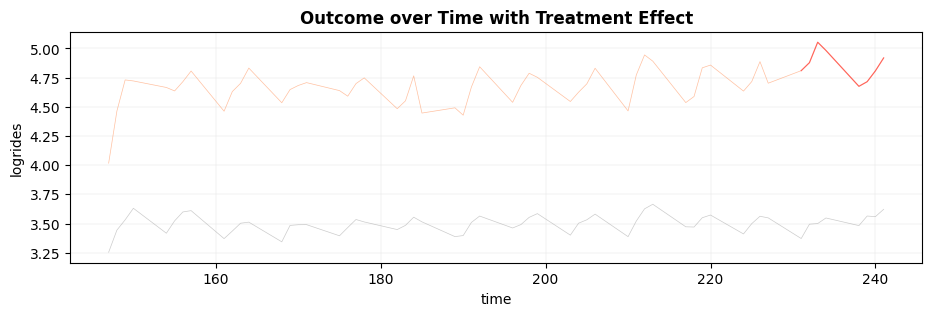

In [49]:
pf.panelview(pipes([drop_weekends])(panel),
             outcome="logrides", time="time", unit="id", treat="treat",
             collapse_to_cohort=True)

# Placebo Test

In [50]:
nweeks = (from_ymd(panel['date'].max()) - from_ymd(panel['date'].min())).days // 7
print(f"Panel has {nweeks} weeks.")

def placebo_dates(df, weekshift):
    df = df.sort_values('date')
    shift = df['date'].apply(from_ymd) + timedelta(days=7 * weekshift)
    df["treat"] = df['UCMP'] & (("2024-08-19" <= shift) & (shift <= "2024-08-22"))
    return df

Panel has 13 weeks.


In [51]:
placebos = [model_did(pipes([drop_weekends, partial(placebo_dates, weekshift=i)])(panel), fe="id + time^transit")
            for i in range(1, nweeks)]

In [79]:
placebo_stat = (1 + sum([np.abs(p._tstat[p._coefnames.index('treat')]) >=
                         np.abs(spec3_model._tstat[spec3_model._coefnames.index('treat')]) for p in placebos])) / (1 + len(placebos))
floor = (1.0 + 0) / (1 + len(placebos))
print(np.round([placebo_stat, floor], 3))

[0.077 0.077]


In [80]:
placebo_tbl = pf.etable([spec3_model] + placebos,
                        # Instead of using bonferonni corrected p values, use p value rank stat computed above.
                        # signif_code=[round(.001/12,5), round(.01/12, 5), round(.05/12, 5)],
                        model_heads=[f"Week -{i}" for i in range(0, nweeks)],
                      labels={"id":"unit FE",
                              "transit": "mode",
                              "time^transit":"time x transit FE",
                              "logrides": "log(rides)"},
                        fe_absent='yes')

with open(placebo_out, "w") as f:
    f.write(placebo_tbl.as_raw_html())

# Commented because I always have to set the FE markers
# !cp {placebo_out} ../../eric-mc2-cv/static/uploads/

placebo_tbl

GT(_tbl_data=  __index_level_0__        __index_level_1__                     0  \
0              coef                    treat  0.235** <br> (0.082)   
1              coef   treat × mode ×  × bike    0.041 <br> (0.089)   
2              coef  treat × mode ×  × train    0.190 <br> (0.151)   
3                fe                  unit FE                     -   
4                fe        time x transit FE                     -   
5             stats             Observations               110,026   
6             stats                       R²                 0.964   

                     1                    2                    3  \
0   0.057 <br> (0.059)   0.002 <br> (0.040)   0.066 <br> (0.056)   
1  -0.016 <br> (0.064)   0.024 <br> (0.028)   0.049 <br> (0.040)   
2  -0.142 <br> (0.071)  -0.078 <br> (0.066)  -0.108 <br> (0.058)   
3                    -                    -                    -   
4                    -                    -                    -   
5              110,026              110,026              110,026   
6                0.964                0.964                0.964   

                      4                      5                    6  \
0  -0.068* <br> (0.033)   -0.103* <br> (0.049)   0.001 <br> (0.030)   
1   0.106* <br> (0.041)  0.172*** <br> (0.049)  -0.128 <br> (0.070)   
2    0.040 <br> (0.042)     0.092 <br> (0.056)  -0.034 <br> (0.037)   
3                     -                      -                    -   
4                     -                      -                    -   
5               110,026                110,026              110,026   
6                 0.964                  0.964                0.964   

                      7                    8                    9  \
0  -0.082* <br> (0.035)  -0.010 <br> (0.036)  -0.007 <br> (0.036)   
1   -0.109 <br> (0.079)  -0.036 <br> (0.065)  -0.046 <br> (0.034)   
2    0.063 <br> (0.049)  -0.001 <br> (0.045)  -0.083 <br> (0.048)   
3                     -                    -                    -   
4                     -                    -                    -   
5               110,026              110,026              110,026   
6                 0.964                0.964                0.964   

                    10                   11                   12  
0   0.030 <br> (0.049)  -0.030 <br> (0.027)  -0.081 <br> (0.055)  
1  -0.012 <br> (0.042)   0.015 <br> (0.028)  -0.092 <br> (0.048)  
2  -0.070 <br> (0.053)   0.055 <br> (0.041)   0.094 <br> (0.055)  
3                    -                    -                    -  
4                    -                    -                    -  
5              110,026              110,026              110,026  
6                0.964                0.964                0.964  , _body=<great_tables._gt_data.Body object at 0x34763feb0>, _boxhead=Boxhead([ColInfo(var='__index_level_0__', type=<ColInfoTypeEnum.row_group: 3>, column_label='__index_level_0__', column_align='center', column_width=None), ColInfo(var='__index_level_1__', type=<ColInfoTypeEnum.stub: 2>, column_label='__index_level_1__', column_align='center', column_width=None), ColInfo(var='0', type=<ColInfoTypeEnum.default: 1>, column_label=Html(text='(1)'), column_align='center', column_width=None), ColInfo(var='1', type=<ColInfoTypeEnum.default: 1>, column_label=Html(text='(2)'), column_align='center', column_width=None), ColInfo(var='2', type=<ColInfoTypeEnum.default: 1>, column_label=Html(text='(3)'), column_align='center', column_width=None), ColInfo(var='3', type=<ColInfoTypeEnum.default: 1>, column_label=Html(text='(4)'), column_align='center', column_width=None), ColInfo(var='4', type=<ColInfoTypeEnum.default: 1>, column_label=Html(text='(5)'), column_align='center', column_width=None), ColInfo(var='5', type=<ColInfoTypeEnum.default: 1>, column_label=Html(text='(6)'), column_align='center', column_width=None), ColInfo(var='6', type=<ColInfoTypeEnum.default: 1>, column_label=Html(text='(7)'), column_align='cent

# Power

In [53]:
mde_data = panel_mde_ai(panel, "transit", "id", "time", "rides", "UCMP", "DNC").reset_index()
mde_data

,transit,n_units,n_treated_obs,mean_y_treated,min_pct_lift,min_daily_lift,min_total_lift
0,bike,1596,172,49.529224,0.112381,261.608561,957.376011
1,train,142,32,1478.749267,0.096340,1139.697590,4558.790359
2,uber,1257,160,820.092806,0.116000,3805.229530,15220.918120


In [54]:
mde_data['min_pct_lift'] = (mde_data['min_pct_lift'] * 100).apply(lambda x: f'{x:.1f}%')
mde_data['min_daily_lift'] = mde_data['min_daily_lift'].astype(int)
mde_data['min_total_lift'] = mde_data['min_total_lift'].astype(int)
mde_data = (mde_data[['transit','min_pct_lift','min_daily_lift','min_total_lift']]
            .rename(columns={'min_pct_lift': 'MDE',
                            'min_daily_lift':'MDE Daily',
                             'min_total_lift':'MDE Total'}))
mde_table = tabulate(mde_data, headers="keys", tablefmt="github", showindex=False)
print(mde_table)

with open(mde_out, 'w') as f:
    f.write(mde_table)

!cp {mde_out} ../../eric-mc2-cv/static/uploads

| transit   | MDE   |   MDE Daily |   MDE Total |
|-----------|-------|-------------|-------------|
| bike      | 11.2% |         261 |         957 |
| train     | 9.6%  |        1139 |        4558 |
| uber      | 11.6% |        3805 |       15220 |


# Interpretation

In [55]:
import numpy as np, pandas as pd
from scipy import stats

def interpret(model, combos, data=None, query=None):
    """
    Converts coefficients into interpretable units.
    Parameters
    ----------
    model : fitted pyfixest model
        Must expose `.coef()`, `._vcov`, and `._df_t`.
        Must be of the form log(y) ~ x
    combos : dict[str, list[str]]
        Mapping from a label to the list of coefficient names to sum.
        Example: {"pretty_name": ["ugly_regression_coef_1", "ugly_regression_coef_2"]}
    """
    b, V = model.coef(), model._vcov
    names = list(b.index)

    # Validate that every requested coefficient exists
    missing = {k: [c for c in cols if c not in names]
               for k, cols in combos.items()}
    missing = {k: v for k, v in missing.items() if v}
    if missing:
        raise KeyError(
            f"Coefficient(s) not found in model: {missing}. "
            f"Available: {names}"
        )

    rows = {}
    for k, cols in combos.items():
        w = pd.Series(0.0, index=names)
        w[cols] = 1
        est = w @ b
        se = np.sqrt(w.values @ V @ w.values)
        p = 2 * stats.t.sf(abs(est / se), model._df_t)
        ci = est + np.array([-1, 1]) * stats.t.ppf(0.975, model._df_t) * se
        rows[k] = dict(est=est, se=se, p=p, lo=ci[0], hi=ci[1],
                       est_pct=100 * np.expm1(est),
                       lo_pct=100 * np.expm1(ci[0]),
                       hi_pct=100 * np.expm1(ci[1]))
        if data is not None:
            y11 = data.query(query + f' & transit == "{k}"')['rides'].sum()
            rows[k]['est_lift'] = round((1 - np.exp(-est)) * y11)
            rows[k]['y11_total'] = round(y11)

    return pd.DataFrame(rows).T

## Coefs

Coefficients (causal):

In [56]:
combos = {"uber": ["treat"], "bike": ["treat", "treat:transit::bike"], "train": ["treat", "treat:transit::train"]}
interpret(spec3_model, combos, panel, 'treat')

,est,se,p,lo,hi,est_pct,lo_pct,hi_pct,est_lift,y11_total
uber,0.234542,0.082257,0.006120,0.069694,0.399389,26.432907,7.218017,49.091360,30953.0,148055.0
bike,0.275738,0.050688,0.000001,0.174156,0.377320,31.750292,19.024152,45.837119,2505.0,10396.0
train,0.424646,0.115939,0.000562,0.192300,0.656993,52.904941,21.203371,92.898273,22307.0,64470.0


In [57]:
combos = {"uber:1": ["band_mile::1.0:DNC"],
          "uber:2": ["band_mile::2.0:DNC"],
          "bike:1": ["band_mile::1.0:DNC", "band_mile::1.0:DNC:transit::bike"],
          "bike:2": ["band_mile::2.0:DNC", "band_mile::2.0:DNC:transit::bike"],
          "train:1": ["band_mile::1.0:DNC", "band_mile::1.0:DNC:transit::train"],
          "train:2": ["band_mile::2.0:DNC", "band_mile::2.0:DNC:transit::train"]}
interpret(spec7_model, combos)

,est,se,p,lo,hi,est_pct,lo_pct,hi_pct
uber:1,0.177132,0.072525,1.783347e-02,0.031788,0.322477,19.378916,3.229895,38.054249
uber:2,0.015314,0.035440,6.673581e-01,-0.055710,0.086337,1.543154,-5.418656,9.017400
bike:1,0.280404,0.050787,9.420702e-07,0.178625,0.382183,32.366427,19.557180,46.548045
bike:2,0.035655,0.028596,2.177311e-01,-0.021652,0.092963,3.629855,-2.141956,9.742095
train:1,0.412810,0.116593,8.212862e-04,0.179152,0.646467,51.105753,19.620293,90.878555
train:2,-0.061003,0.035922,9.511431e-02,-0.132992,0.010985,-5.917997,-12.452783,1.104564


Coefficients (citywide):

In [58]:
model_citywide(pipes([drop_weekends])(panel)).summary()

###

Estimation:  OLS
Dep. var.: logrides, Fixed effects: id
sample: None = all
Inference:  CRV1
Observations:  110026

| Coefficient        |   Estimate |   Std. Error |   t value |   Pr(>|t|) |   2.5% |   97.5% |
|:-------------------|-----------:|-------------:|----------:|-----------:|-------:|--------:|
| treat              |      0.275 |        0.044 |     6.231 |      0.000 |  0.188 |   0.361 |
| DNC                |     -0.027 |        0.011 |    -2.319 |      0.020 | -0.049 |  -0.004 |
| DNC:transit::bike  |      0.045 |        0.018 |     2.546 |      0.011 |  0.010 |   0.080 |
| DNC:transit::train |     -0.043 |        0.019 |    -2.305 |      0.021 | -0.079 |  -0.006 |
---
RMSE: 0.069 R2: 0.962 R2 Within: 0.001 


In [59]:
combos = {"uber": ["DNC"], "bike": ["DNC", "DNC:transit::bike"], "train": ["DNC", "DNC:transit::train"]}
interpret(model_citywide(pipes([drop_weekends])(panel)), combos, panel, '(UCMP == 0) & (DNC == 1)')

,est,se,p,lo,hi,est_pct,lo_pct,hi_pct,est_lift,y11_total
uber,-0.026640,0.011488,0.020465,-0.049166,-0.004115,-2.628875,-4.797675,-0.410668,-21780.0,806727.0
bike,0.018462,0.013686,0.177468,-0.008374,0.045298,1.863339,-0.833952,4.633995,2553.0,139585.0
train,-0.069527,0.014528,0.000002,-0.098014,-0.041040,-6.716502,-9.336341,-4.020961,-83620.0,1161369.0


### Battery coefs

In [60]:
(pd.concat([interpret(spec3_model, combos, panel, 'treat'),
           interpret(spec4_model, combos, panel, 'treat'),
           interpret(spec1_model, combos, panel, 'treat'),
           interpret(spec2_model, combos, panel, 'treat'),
           interpret(spec5_model, combos, panel, 'treat'),
           interpret(spec6_model, combos, panel, 'treat')],
          keys=['spec 3', 'spec 4', 'spec 1', 'spec 2', 'spec 5', 'spec 6'])
 .filter(['est','p','lo_pct','hi_pct'])
 .assign(sig_level = lambda x: x['p'] < .05))

KeyError: "Coefficient(s) not found in model: {'uber': ['DNC'], 'bike': ['DNC', 'DNC:transit::bike'], 'train': ['DNC', 'DNC:transit::train']}. Available: [np.str_('treat'), np.str_('treat:transit::bike'), np.str_('treat:transit::train')]"

## Totals

Total rides at and during DNC:

In [ ]:
panel.groupby(['transit','UCMP','DNC'])['rides'].sum().xs(1, 'index', 'DNC').xs(1, 'index', 'UCMP')

Total rides during DNC citywide:

In [ ]:
panel.groupby(['transit','UCMP','DNC'])['rides'].sum().xs(1, 'index', 'DNC').xs(0, 'index', 'UCMP')

## Daily Changes

Change in daily transit averages at DNC:

In [ ]:
treat_change = (panel[panel['UCMP']==1]
.groupby(["time","DNC","transit"], as_index=False)
.agg(daily_total=("rides", "sum"))
.groupby(["transit","DNC"])
.agg(mean_daily_total=("daily_total", "mean")))
treat_change.xs(1, "index", "DNC") - treat_change.xs(0, "index", "DNC")

Change in daily transit averages citywide:

In [ ]:
control_change = (panel[panel['UCMP']==0]
.groupby(["time","DNC","transit"], as_index=False)
.agg(daily_total=("rides", "sum"))
.groupby(["transit","DNC"])
.agg(mean_daily_total=("daily_total", "mean")))
control_change.xs(1, "index", "DNC") - control_change.xs(0, "index", "DNC")